Data loaded successfully. Shape: (395, 33)
Preprocessing completed. Columns after encoding: Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3', 'school_MS', 'sex_M', 'address_U', 'famsize_LE3', 'Pstatus_T',
       'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher',
       'Fjob_health', 'Fjob_other', 'Fjob_services', 'Fjob_teacher',
       'reason_home', 'reason_other', 'reason_reputation', 'guardian_mother',
       'guardian_other', 'schoolsup_yes', 'famsup_yes', 'paid_yes',
       'activities_yes', 'nursery_yes', 'higher_yes', 'internet_yes',
       'romantic_yes', 'parent_edu_index', 'pass_fail'],
      dtype='object')

Descriptive statistics for numeric features:
              age        Medu       Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.00000  395.000000  395.000000  395.000000   
mean     0.242315    0.687342    0.6

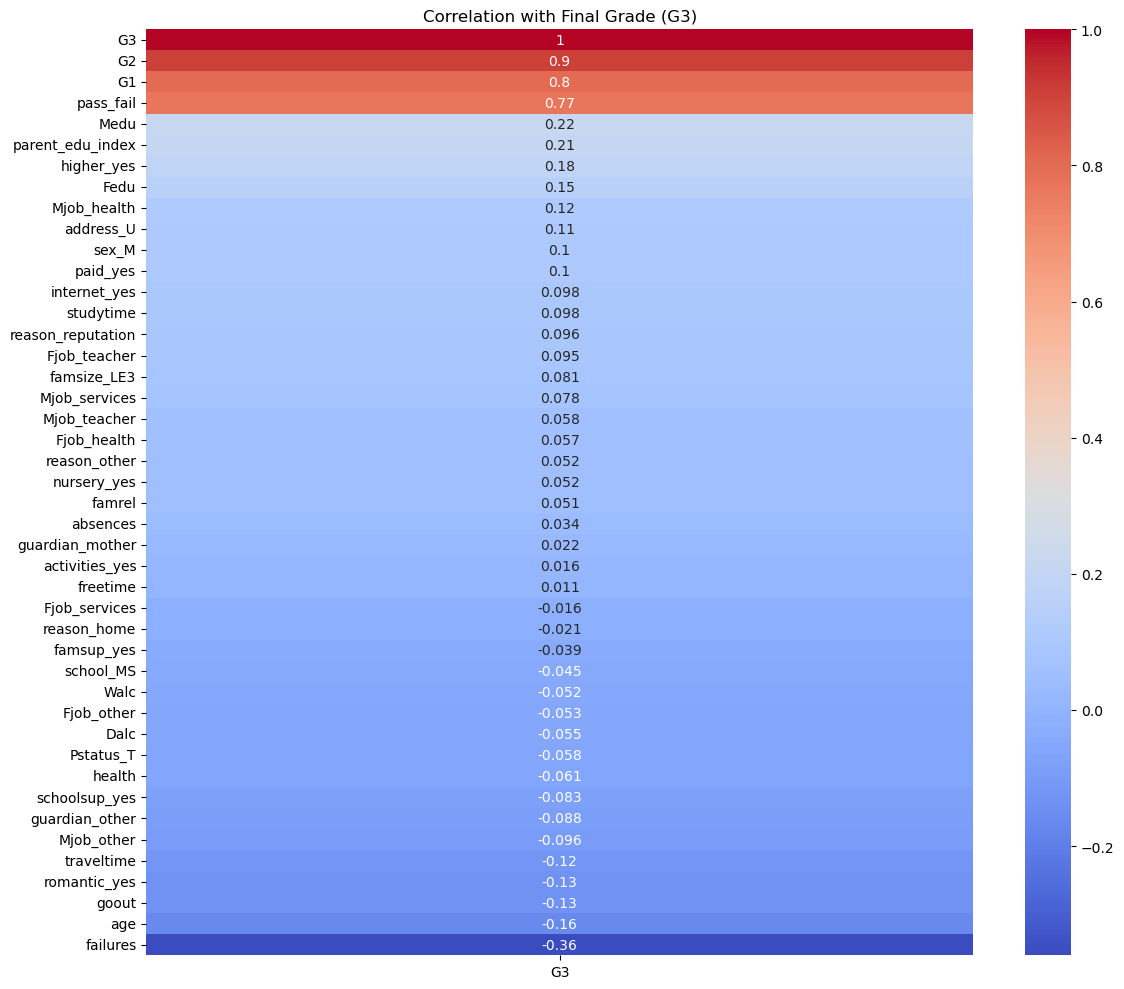

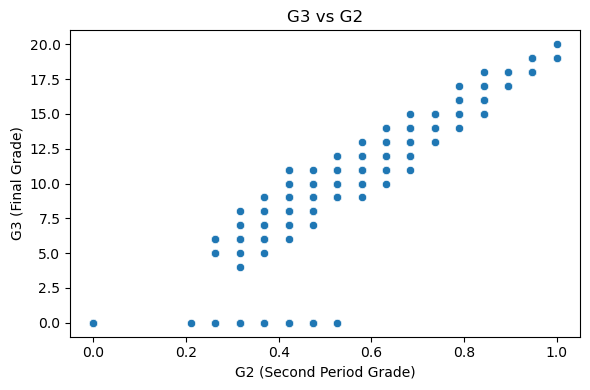

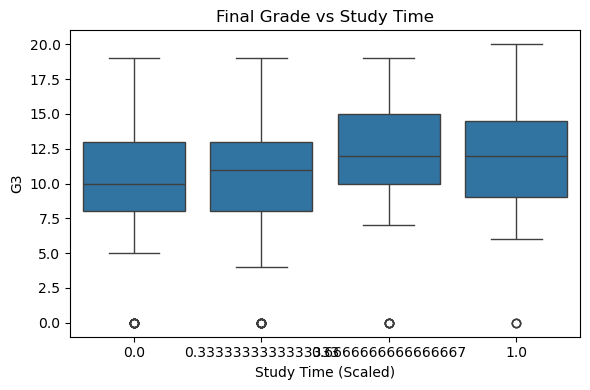


Regression Metrics for Linear Regression:
R2: 0.724
MAE: 1.647
RMSE: 2.378

Regression Metrics for Ridge Regression (Best Alpha = 0.1):
R2: 0.725
MAE: 1.642
RMSE: 2.374

Regression Metrics for Random Forest Regression (Best Params):
R2: 0.815
MAE: 1.174
RMSE: 1.949


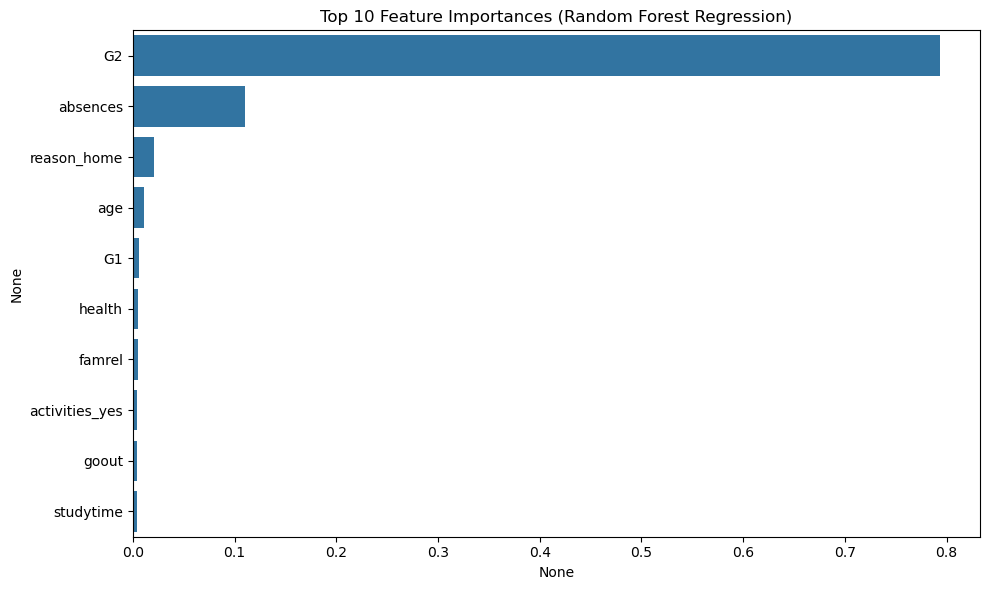


Classification Metrics for Logistic Regression:
Accuracy: 0.861
Precision: 0.873
Recall: 0.923
F1 Score: 0.897
Confusion Matrix:
 [[20  7]
 [ 4 48]]

Classification Metrics for SVM Classifier (Best Params):
Accuracy: 0.861
Precision: 0.873
Recall: 0.923
F1 Score: 0.897
Confusion Matrix:
 [[20  7]
 [ 4 48]]

Classification Metrics for Random Forest Classifier (Best Params):
Accuracy: 0.899
Precision: 0.94
Recall: 0.904
F1 Score: 0.922
Confusion Matrix:
 [[24  3]
 [ 5 47]]


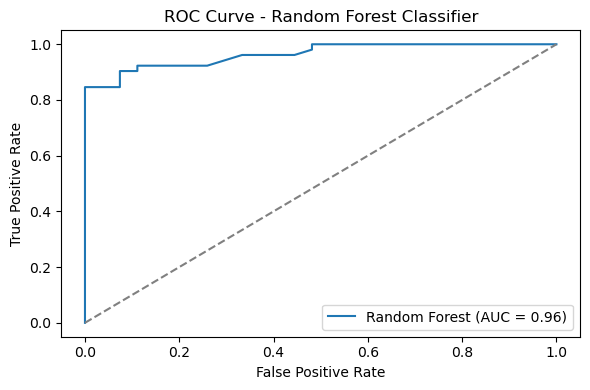

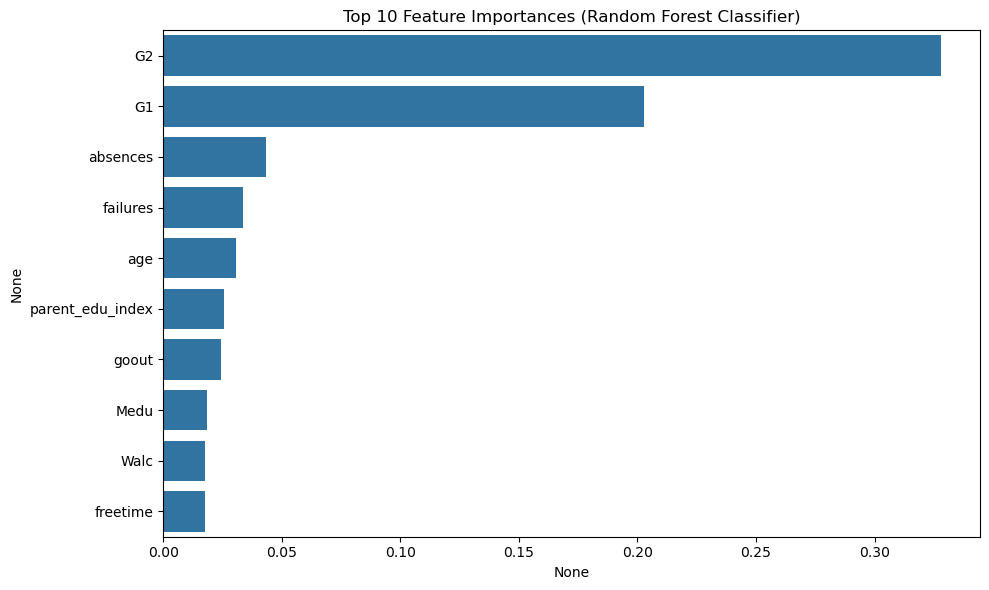


Script completed successfully. All tables, plots, and metrics are generated.


In [1]:
# -----------------------
# Section 1: Data Loading
# -----------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
# Load datasets
mat_data = pd.read_csv('/Users/patrickpatel/Downloads/student-mat.csv', sep=';')
por_data = pd.read_csv('/Users/patrickpatel/Downloads/student-por.csv', sep=';')

# Focus on Mathematics dataset
df = mat_data.copy()
print("Data loaded successfully. Shape:", df.shape)

# -------------------------------
# Section 2: Data Preprocessing
# -------------------------------

# Encode categorical variables using one-hot encoding
categorical_cols = df.select_dtypes(include='object').columns
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Scale numeric features
numeric_cols = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 
                'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 
                'absences', 'G1', 'G2']

scaler = MinMaxScaler()
df_encoded[numeric_cols] = scaler.fit_transform(df_encoded[numeric_cols])

# Create parental education index
df_encoded['parent_edu_index'] = (df_encoded['Medu'] + df_encoded['Fedu']) / 2

# Create binary pass/fail label (G3 >= 10 = pass)
df_encoded['pass_fail'] = df['G3'].apply(lambda x: 1 if x >= 10 else 0)

print("Preprocessing completed. Columns after encoding:", df_encoded.columns)

# -----------------------------------
# Section 3: Exploratory Data Analysis
# -----------------------------------

# Descriptive statistics
print("\nDescriptive statistics for numeric features:")
print(df_encoded[numeric_cols + ['G3']].describe())

# Correlation matrix
corr_matrix = df_encoded.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix[['G3']].sort_values(by='G3', ascending=False), annot=True, cmap='coolwarm')
plt.title('Correlation with Final Grade (G3)')
plt.tight_layout()
plt.savefig('correlation_g3.png')
plt.show()

# Scatterplot G3 vs G2
plt.figure(figsize=(6,4))
sns.scatterplot(x='G2', y='G3', data=df_encoded)
plt.title('G3 vs G2')
plt.xlabel('G2 (Second Period Grade)')
plt.ylabel('G3 (Final Grade)')
plt.tight_layout()
plt.savefig('scatter_g2_g3.png')
plt.show()

# Boxplot of G3 vs studytime
plt.figure(figsize=(6,4))
sns.boxplot(x='studytime', y='G3', data=df_encoded)
plt.title('Final Grade vs Study Time')
plt.xlabel('Study Time (Scaled)')
plt.ylabel('G3')
plt.tight_layout()
plt.savefig('boxplot_studytime_g3.png')
plt.show()

# -------------------------------
# Section 4: Regression Modeling
# -------------------------------

# Define features and target
X = df_encoded.drop(['G3', 'pass_fail'], axis=1)
y = df_encoded['G3']

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Ridge Regression with hyperparameter tuning
ridge_params = {'alpha':[0.01, 0.1, 1.0, 10, 50]}
ridge = Ridge()
ridge_grid = GridSearchCV(ridge, ridge_params, cv=5)
ridge_grid.fit(X_train, y_train)
y_pred_ridge = ridge_grid.predict(X_test)

# Random Forest Regression with hyperparameter tuning
rf_params = {'n_estimators':[100, 200], 'max_depth':[5,10, None], 'min_samples_split':[2,5]}
rf_reg = GridSearchCV(RandomForestRegressor(random_state=42), rf_params, cv=5)
rf_reg.fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)

# Regression Metrics
def regression_metrics(y_true, y_pred, model_name):
    print(f"\nRegression Metrics for {model_name}:")
    print("R2:", round(r2_score(y_true, y_pred), 3))
    print("MAE:", round(mean_absolute_error(y_true, y_pred), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_true, y_pred)), 3))

regression_metrics(y_test, y_pred_lr, "Linear Regression")
regression_metrics(y_test, y_pred_ridge, "Ridge Regression (Best Alpha = {})".format(ridge_grid.best_params_['alpha']))
regression_metrics(y_test, y_pred_rf, "Random Forest Regression (Best Params)")

# Feature importance from best Random Forest
best_rf = rf_reg.best_estimator_
importances = best_rf.feature_importances_
feat_importance = pd.Series(importances, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(x=feat_importance[:10], y=feat_importance.index[:10])
plt.title('Top 10 Feature Importances (Random Forest Regression)')
plt.tight_layout()
plt.savefig('feature_importance_rf_reg.png')
plt.show()

# --------------------------------
# Section 5: Classification Modeling
# --------------------------------

# Define target for classification
y_class = df_encoded['pass_fail']

# Split data
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_c, y_train_c)
y_pred_log = log_reg.predict(X_test_c)

# SVM Classifier with GridSearch
svm_params = {'C':[0.1,1,10], 'gamma':[0.01,0.1,1], 'kernel':['rbf']}
svm_clf = GridSearchCV(SVC(probability=True), svm_params, cv=5)
svm_clf.fit(X_train_c, y_train_c)
y_pred_svm = svm_clf.predict(X_test_c)

# Random Forest Classifier with GridSearch
rf_params_clf = {'n_estimators':[100,200], 'max_depth':[5,10,None], 'min_samples_split':[2,5]}
rf_clf = GridSearchCV(RandomForestClassifier(random_state=42), rf_params_clf, cv=5)
rf_clf.fit(X_train_c, y_train_c)
y_pred_rf_clf = rf_clf.predict(X_test_c)

# Classification Metrics
def classification_metrics(y_true, y_pred, model_name):
    print(f"\nClassification Metrics for {model_name}:")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 3))
    print("Precision:", round(precision_score(y_true, y_pred), 3))
    print("Recall:", round(recall_score(y_true, y_pred), 3))
    print("F1 Score:", round(f1_score(y_true, y_pred), 3))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))

classification_metrics(y_test_c, y_pred_log, "Logistic Regression")
classification_metrics(y_test_c, y_pred_svm, "SVM Classifier (Best Params)")
classification_metrics(y_test_c, y_pred_rf_clf, "Random Forest Classifier (Best Params)")

# ROC Curve for best Random Forest Classifier
best_rf_clf = rf_clf.best_estimator_
y_prob_rf = best_rf_clf.predict_proba(X_test_c)[:,1]
fpr, tpr, thresholds = roc_curve(y_test_c, y_prob_rf)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], linestyle='--', color='grey')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest Classifier')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_rf_classifier.png')
plt.show()

# -------------------------------
# Section 6: Feature Importance Analysis (Classification)
# -------------------------------
importances_clf = best_rf_clf.feature_importances_
feat_importance_clf = pd.Series(importances_clf, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(x=feat_importance_clf[:10], y=feat_importance_clf.index[:10])
plt.title('Top 10 Feature Importances (Random Forest Classifier)')
plt.tight_layout()
plt.savefig('feature_importance_rf_clf.png')
plt.show()

print("\nScript completed successfully. All tables, plots, and metrics are generated.")
